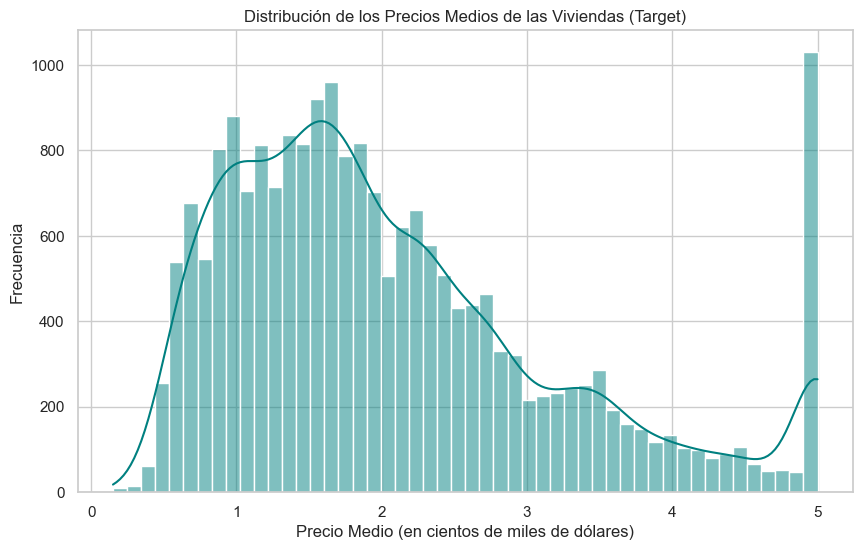

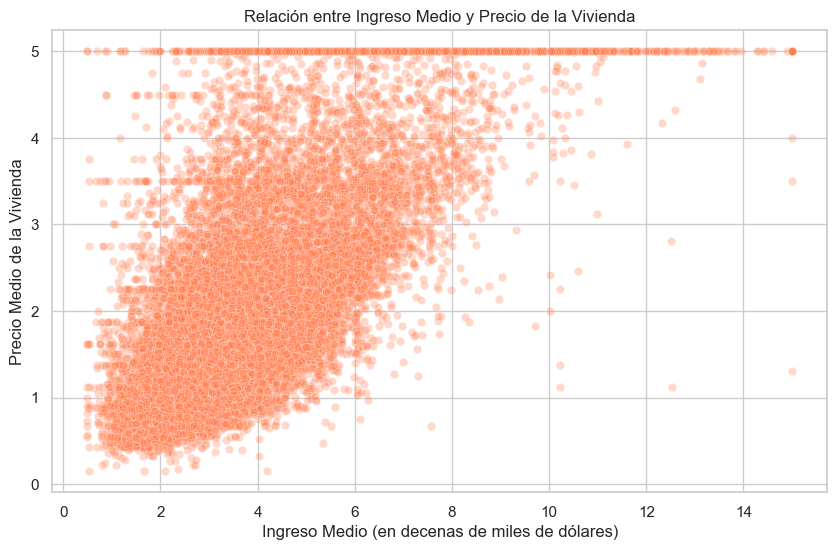

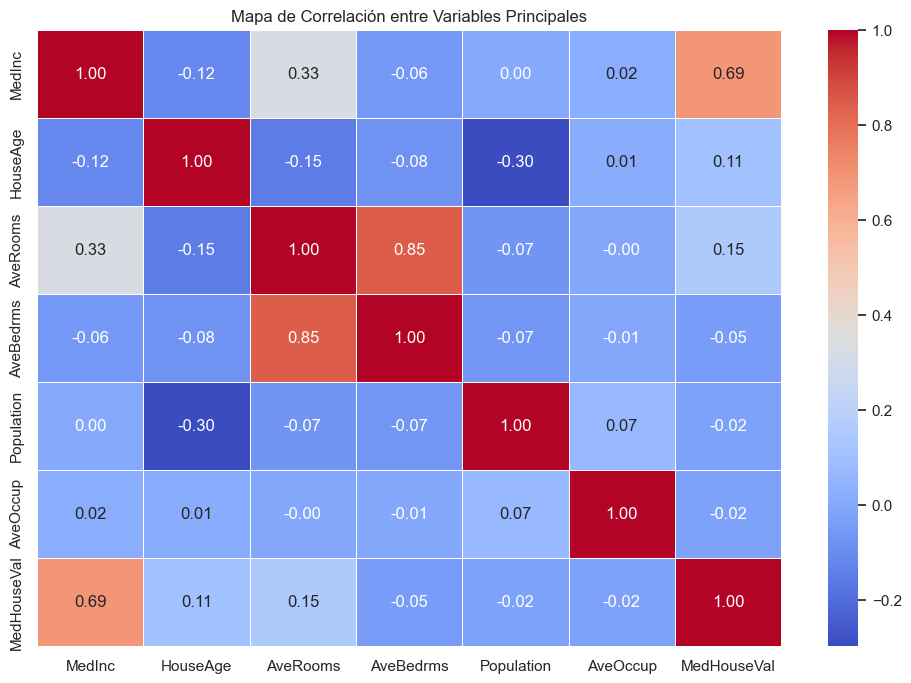

In [2]:
# Exploración de Datos y Visualización (EDA)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargar los datos limpios
df = pd.read_csv('../datos/datos_limp/viviendas_limp.csv')

# Configurar el estilo de las graficas
sns.set_theme(style="whitegrid")

# Grafica 1: Distribución del precio de las viviendas (Target)
plt.figure(figsize=(10, 6))
sns.histplot(df['MedHouseVal'], bins=50, kde=True, color='teal')
plt.title('Distribución de los Precios Medios de las Viviendas (Target)')
plt.xlabel('Precio Medio (en cientos de miles de dólares)')
plt.ylabel('Frecuencia')
plt.show()

# Grafica 2: Relación entre Ingreso Medio y Precio de la Vivienda
plt.figure(figsize=(10, 6))
sns.scatterplot(x='MedInc', y='MedHouseVal', data=df, alpha=0.3, color='coral')
plt.title('Relación entre Ingreso Medio y Precio de la Vivienda')
plt.xlabel('Ingreso Medio (en decenas de miles de dólares)')
plt.ylabel('Precio Medio de la Vivienda')
plt.show()

# Grafica 3: Mapa de correlación (Heatmap)
plt.figure(figsize=(12, 8))
# Seleccionamos solo las variables numéricas principales para el mapa de calor
cols_numericas = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'MedHouseVal']
matriz_correlacion = df[cols_numericas].corr()

sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Mapa de Correlación entre Variables Principales')
plt.show()

In [21]:
import os
import mlflow
import pandas as pd

# Llave maestra
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Apuntamos a la carpeta NUEVA y limpia
ruta_limpia = os.path.abspath("../mlruns_final")
mlflow.set_tracking_uri(ruta_limpia)

try:
    # Traemos el experimento
    df_mlflow = mlflow.search_runs(experiment_names=["Actividad5_Regresion_Viviendas"])
    
    # Extraemos dinámicamente las columnas
    columnas_disponibles = df_mlflow.columns
    columnas_clave = [col for col in [
        'tags.mlflow.runName', 
        'metrics.R2', 'metrics.MAE', 'metrics.RMSE',
        'params.alpha', 'params.max_depth', 'params.n_estimators'
    ] if col in columnas_disponibles]
    
    # Mostrar el panel
    print("\n--- PANEL DE REGISTROS DE MLFLOW ---")
    display(df_mlflow[columnas_clave])
    
except Exception as e:
    print("Error:", e)


--- PANEL DE REGISTROS DE MLFLOW ---


,tags.mlflow.runName,metrics.R2,metrics.MAE,metrics.RMSE,params.alpha,params.max_depth,params.n_estimators
0,Modelo_XGBoost,0.829509,0.314610,0.472665,None,5,100
1,Modelo_Ridge,0.576324,0.533507,0.745110,10.0,None,None
